# <span style="color: DeepSkyBlue;">Climate and Groundwater Analysis of Payson, Arizona</span>
Josh Hernandez<br>  
University of Colorado Boulder<br>  
DTSA 4741-Modeling Climate Anomalies with Statistical Analysis<br>  


# <span style="color: DeepSkyBlue;">Introduction</span>

The Mogollon Rim is a unique mountainous region in Central Arizona just 90 minutes outside of Phoenix that features steep mountain country at 8000 ft, Ponderosa forests, and a diverse hydrological habitat. This project uses the NOAA NCEI API Access Data Service and the USGS Water Data API to study climate and groundwater observations near Payson, Arizona in the Mogollon Rim. The NOAA station and USGS well used for data collection are less than a mile apart in the Tonto Basin hydrologic region. NOAA daily summaries are requested for station USW00093139 from August 25, 2021 through December 31, 2025. The overlapping USGS daily mean groundwater record for well USGS-341408111212001 is measured for August 26, 2021 through December 31, 2025. 

# <span style="color: DeepSkyBlue;">Data Collection and Processing</span>


## <span style="color: DeepSkyBlue;">Imports</span>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests

## <span style="color: DeepSkyBlue;">Load the Payson NOAA Data</span>

The National Oceanic and Atomospheric Administration(NOAA) NCEI Access Data Service API endpoint retrieves daily maximum temperature (TMAX), minimum temperature (TMIN), and precipitation (PRCP) for station USW00093139 (Payson) from 2021-08-25 through 2025-12-31 and saved to a CSV file. The USGS daily mean groundwater series begins one day later, so the shared date range starts 2021-08-26. We use the to_numeric method on the JSON data received from the API request since NOAA station data may contain strings. The NOAA v1 endpoint data request does not require an API token but does need specific parameters as outlined by the API documentation for a successful GET request to occur. The data is sourced from the endpoint at the NOAA National Centers for Environmental Information(NOAA NCEI, 2026).

Variable definitions:  
- TMAX: maximum daily temperature (°F)  
- TMIN: minimum daily temperature (°F)  
- PRCP: daily precipitation (inches)  

In [2]:
url = "https://www.ncei.noaa.gov/access/services/data/v1"
params = {
    "dataset": "daily-summaries",
    "stations": "USW00093139",  # Payson station
    "startDate": "2021-08-25",
    "endDate": "2025-12-31",
    "dataTypes": "TMAX,TMIN,PRCP",
    "format": "json",
    "units": "standard",
}

response = requests.get(url, params=params, timeout=60)
print("HTTP Response Status:", response.status_code)

if response.ok:
    df_noaa = pd.DataFrame(response.json())[["DATE", "TMAX", "TMIN", "PRCP"]]
    df_noaa["DATE"] = pd.to_datetime(df_noaa["DATE"])
    for column in ["TMAX", "TMIN", "PRCP"]:
        df_noaa[column] = pd.to_numeric(df_noaa[column], errors="coerce")

    print(f"Features:\n{df_noaa.head(10)}")
    print(f"Data Types:\n{df_noaa.dtypes}")
    print(f"Missing Values:\n{df_noaa.isnull().sum()}")
    print(f"Date coverage: {df_noaa['DATE'].min().date()} to {df_noaa['DATE'].max().date()}")
    df_noaa.to_csv("payson_climate_data.csv", index=False)
else:
    print("Error:", response.text)


HTTP Response Status: 200
Features:
        DATE  TMAX  TMIN  PRCP
0 2021-08-25  93.0  56.0  0.00
1 2021-08-26  93.0  60.0  0.00
2 2021-08-27  94.0  60.0  0.00
3 2021-08-28  92.0  59.0  0.00
4 2021-08-29  91.0  61.0  0.00
5 2021-08-30  92.0  61.0  0.00
6 2021-08-31  87.0  63.0  0.00
7 2021-09-01  79.0  62.0  1.39
8 2021-09-02  79.0  58.0  0.07
9 2021-09-03  85.0  55.0  0.01
Data Types:
DATE    datetime64[ns]
TMAX           float64
TMIN           float64
PRCP           float64
dtype: object
Missing Values:
DATE    0
TMAX    2
TMIN    2
PRCP    2
dtype: int64
Date coverage: 2021-08-25 to 2025-12-31


## <span style="color: DeepSkyBlue;">NOAA Data Summary and Visualizations</span>
We will statistically describe the NOAA climate data and plot each dataset individually over the time interval(08/21-12/25). 

In [3]:
# Data summary for NOAA observations
df_noaa.describe()

,DATE,TMAX,TMIN,PRCP
count,1590,1588.000000,1588.000000,1588.000000
mean,2023-10-28 12:00:00,73.192065,40.977330,0.049553
min,2021-08-25 00:00:00,35.000000,7.000000,0.000000
25%,2022-09-26 06:00:00,61.000000,29.000000,0.000000
50%,2023-10-28 12:00:00,74.000000,39.000000,0.000000
75%,2024-11-28 18:00:00,87.000000,53.000000,0.000000
max,2025-12-31 00:00:00,105.000000,73.000000,1.620000
std,NaN,15.257802,14.242547,0.186908


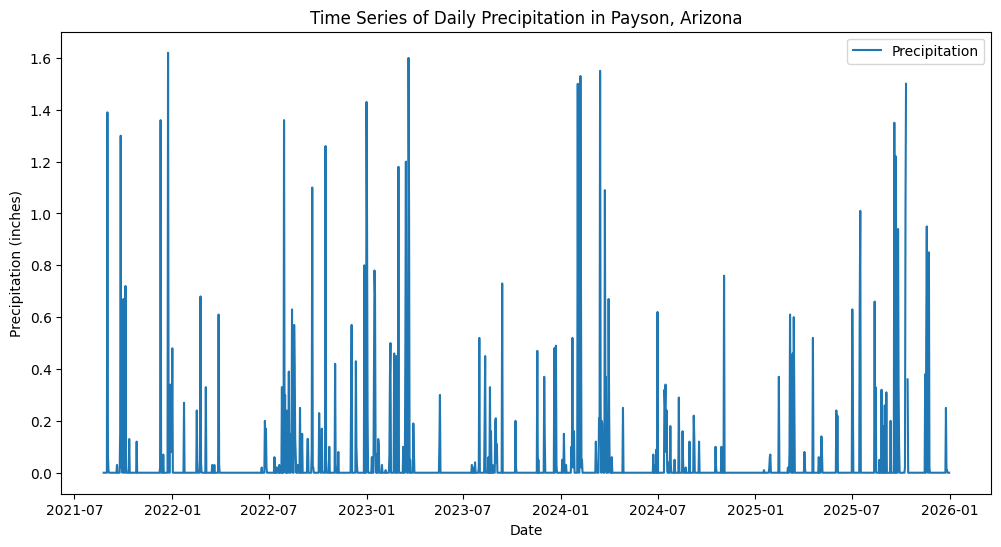

In [4]:
# Time series of daily precipitation
plt.figure(figsize=(12, 6))
plt.plot(df_noaa["DATE"], df_noaa["PRCP"], label="Precipitation")
plt.xlabel("Date")
plt.ylabel("Precipitation (inches)")
plt.title("Time Series of Daily Precipitation in Payson, Arizona")
plt.legend()
plt.show()

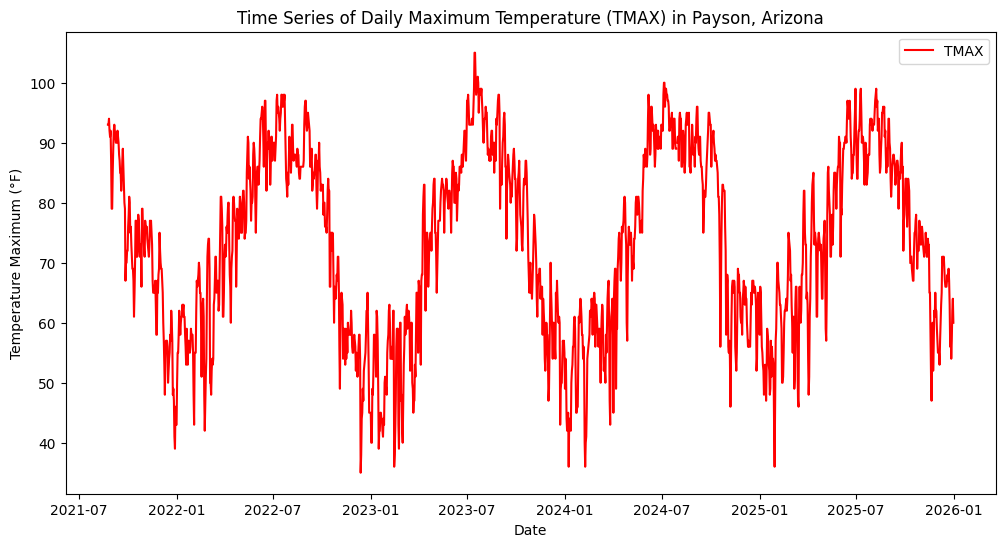

In [5]:
# Time series of daily maximum temperature
plt.figure(figsize=(12, 6))
plt.plot(df_noaa["DATE"], df_noaa["TMAX"], label="TMAX", color="red")
plt.xlabel("Date")
plt.ylabel("Temperature Maximum (°F)")
plt.title("Time Series of Daily Maximum Temperature (TMAX) in Payson, Arizona")
plt.legend()
plt.show()

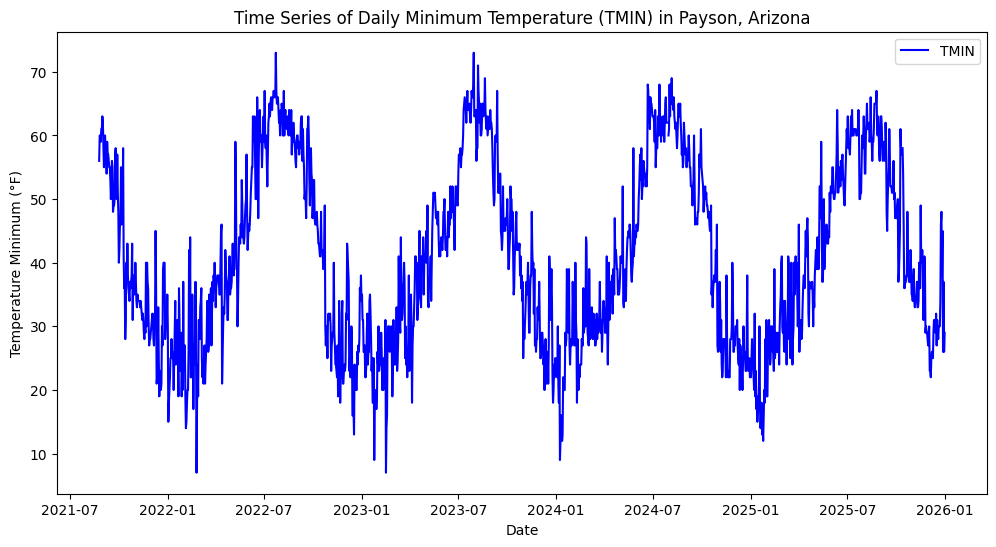

In [6]:
# Time series of daily minimum temperature
plt.figure(figsize=(12, 6))
plt.plot(df_noaa["DATE"], df_noaa["TMIN"], label="TMIN", color="blue")
plt.xlabel("Date")
plt.ylabel("Temperature Minimum (°F)")
plt.title("Time Series of Daily Minimum Temperature (TMIN) in Payson, Arizona")
plt.legend()
plt.show()

## <span style="color: DeepSkyBlue;">Distribution of Climate Time Series</span>
We will plot the distributions(histograms) of the three daily climate variables from NOAA. 

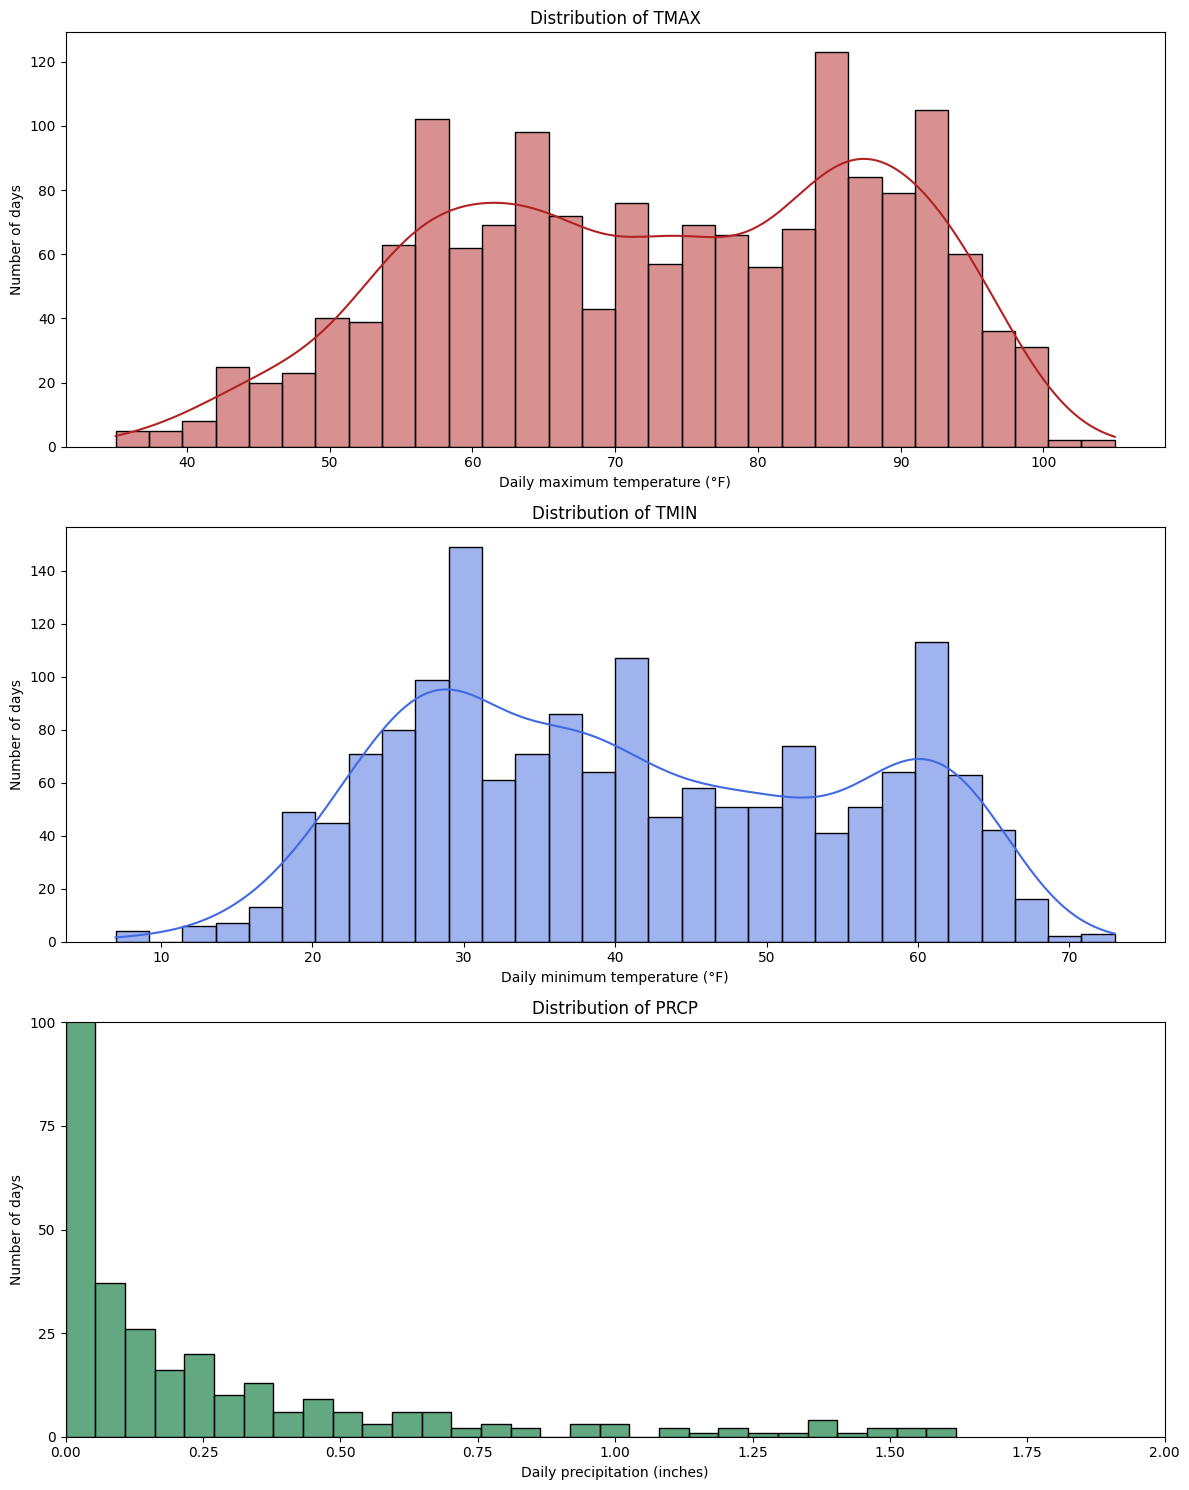

In [70]:
# Distributions of daily TMAX, TMIN, and PRCP
fig, axes = plt.subplots(3, 1, figsize=(12, 15))

plot_settings = [
    ("TMAX", "Daily maximum temperature (°F)", "firebrick", True),
    ("TMIN", "Daily minimum temperature (°F)", "royalblue", True),
    ("PRCP", "Daily precipitation (inches)", "seagreen", False),
]

for axis, (column, label, color, show_kde) in zip(axes, plot_settings):
    values = pd.to_numeric(df_noaa[column], errors="coerce").dropna()
    sns.histplot(values, bins=30, kde=show_kde, color=color, ax=axis)
    axis.set_title(f"Distribution of {column}")
    axis.set_xlabel(label)
    axis.set_ylabel("Number of days")
    
    # Adjust prcp for better visibility
    if column == "PRCP":
        axis.set_xlim(0, 2,)
        axis.set_ylim(0, 100)
        axis.set_yticks([0, 25, 50, 75, 100])

plt.tight_layout()
plt.show()


## <span style="color: DeepSkyBlue;">USGS Daily Groundwater Data for Payson, Arizona</span>

This well(A-10-10 05CCA or USFS-341408111212001) is about less than a mile from the Payson NOAA station(GHCND USW00093139).  The recorded daily means begin on August 26, 2021. For comparison with the NOAA data, we use data through December 31, 2025. Groundwater values are in feet below land surface. We will also be merging the GWL data with the previous NOAA data to allow for matched comparisons and data visualizations. The data is sourced from the United States Geological Survey Water Data API service (U.S. Geological Survey, 2026).

In [58]:
# Fetch USGS daily mean groundwater measurements
# GWL = groundwater level; NOAA = National Oceanic and Atmospheric Administration
site = "USGS-341408111212001"
start = "2021-08-25"
end = "2025-12-31"

url = "https://api.waterdata.usgs.gov/ogcapi/v1/collections/daily/items"
params = {
    "f": "json",
    "monitoring_location_id": site,
    "parameter_code": "72019",
    "statistic_id": "00003",
    "datetime": f"{start}/{end}",
    "limit": 5000,
}
# HTTP API call to USGS
response = requests.get(url, params=params, timeout=60)
response.raise_for_status()
df_gwl = pd.DataFrame(item["properties"] for item in response.json()["features"])

# Process USGS data and merge with NOAA data
def process_usgs_data(df_gwl, df_noaa):
    if df_gwl.empty:
        print("No USGS groundwater measurements returned.")
        return pd.DataFrame()

    groundwater = df_gwl.rename(
        columns={"time": "DATE", "value": "GWL", "unit_of_measure": "UNIT"}
    )[["DATE", "GWL", "UNIT"]].copy()
    groundwater["DATE"] = pd.to_datetime(groundwater["DATE"])
    groundwater["GWL"] = pd.to_numeric(groundwater["GWL"], errors="coerce")
    groundwater = groundwater.sort_values("DATE").reset_index(drop=True)

    df_merged = df_noaa.merge(groundwater[["DATE", "GWL"]], on="DATE", how="inner")

    #Summary of Merged Data
    print(f"USGS daily GWL mean count: {len(groundwater)}")
    print("\nGroundwater Level (GWL) Preview:")
    print(groundwater[["DATE", "GWL", "UNIT"]].head(5).to_string(index=False, col_space=10))
    print("\nStatistical summary of Groundwater Level (GWL):")
    print(df_merged["GWL"].describe(), "\n")

    # Print Merged Column
    print("Merged Data Preview:")
    print(f"Matched NOAA-USGS dates: {len(df_merged)}")
    if not df_merged.empty:
        print(f"Shared date coverage: {df_merged['DATE'].min().date()} to {df_merged['DATE'].max().date()}")
    return df_merged

df_merged = process_usgs_data(df_gwl, df_noaa)
print(df_merged.head(10).to_string(index=False, col_space=10))


USGS daily GWL mean count: 1587

Groundwater Level (GWL) Preview:
      DATE        GWL       UNIT
2021-08-26      32.47         ft
2021-08-27      32.42         ft
2021-08-28      32.39         ft
2021-08-29      32.35         ft
2021-08-30      32.31         ft

Statistical summary of Groundwater Level (GWL):
count    1587.000000
mean       30.224222
std         1.154716
min        27.510000
25%        29.545000
50%        30.580000
75%        31.120000
max        32.470000
Name: GWL, dtype: float64 

Merged Data Preview:
Matched NOAA-USGS dates: 1587
Shared date coverage: 2021-08-26 to 2025-12-31
      DATE       TMAX       TMIN       PRCP        GWL
2021-08-26       93.0       60.0       0.00      32.47
2021-08-27       94.0       60.0       0.00      32.42
2021-08-28       92.0       59.0       0.00      32.39
2021-08-29       91.0       61.0       0.00      32.35
2021-08-30       92.0       61.0       0.00      32.31
2021-08-31       87.0       63.0       0.00      32.26
2021-09-

## <span style="color: DeepSkyBlue;">Daily Groundwater and Climate Combined Time Series</span>
Merged by date on the x-axis and spread out by 6 month intervals. 

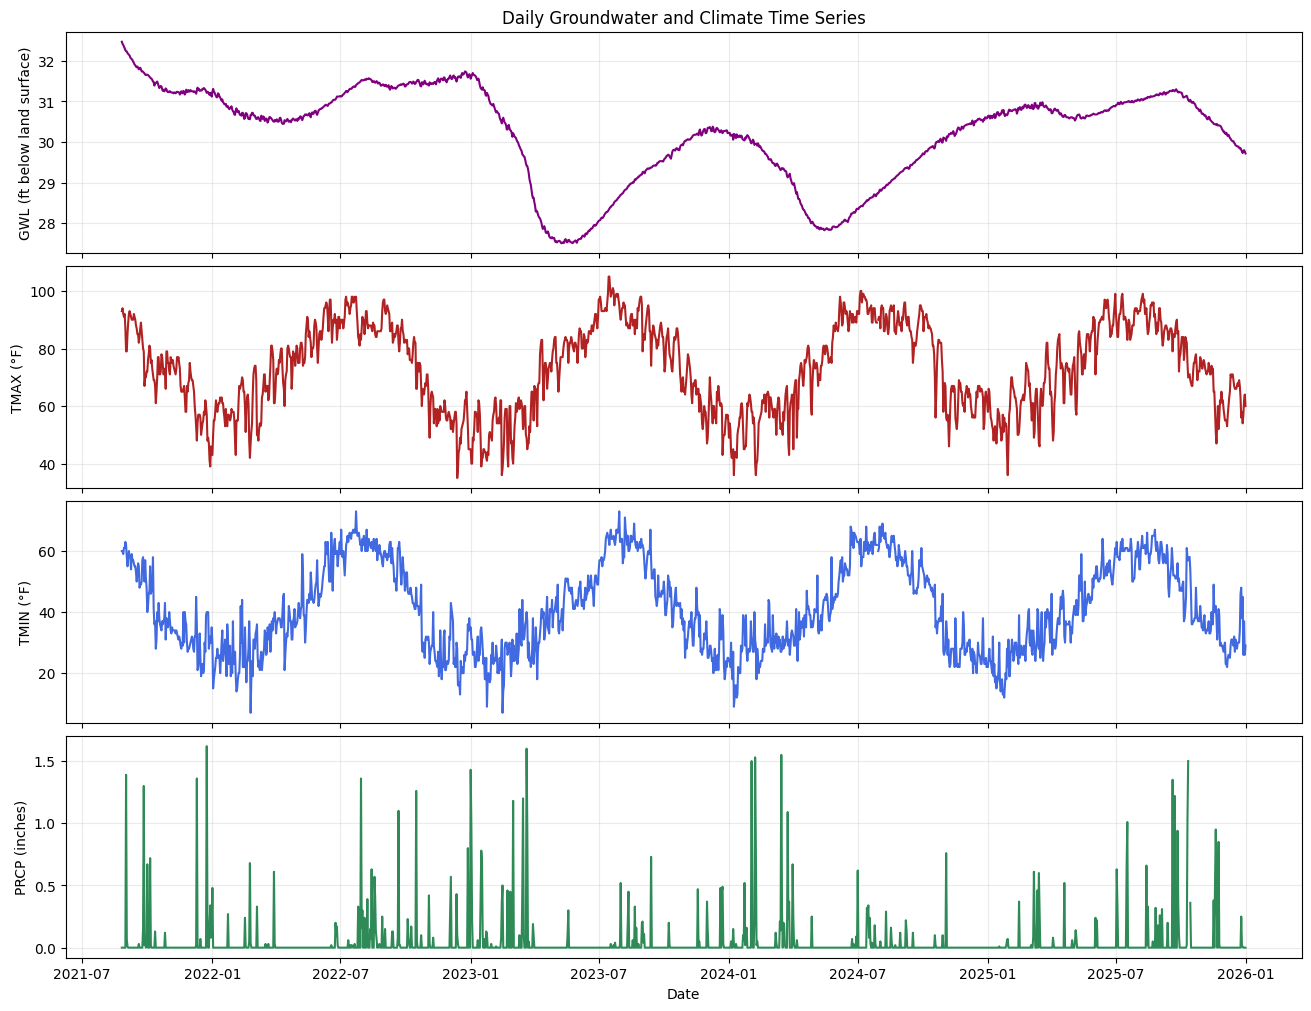

In [37]:
# Time series of matched groundwater and climate observations
if df_merged is None:
    print("No matched groundwater and climate observations found.")
else:
    plot_specs = [
        ("GWL", "GWL (ft below land surface)", "purple"),
        ("TMAX", "TMAX (°F)", "firebrick"),
        ("TMIN", "TMIN (°F)", "royalblue"),
        ("PRCP", "PRCP (inches)", "seagreen"),
    ]
    fig, axes = plt.subplots(
        nrows=4, ncols=1, figsize=(13, 10), sharex=True, constrained_layout=True
    )

    for axis, (column, label, color) in zip(axes, plot_specs):
        axis.plot(df_merged["DATE"], df_merged[column], color=color)
        axis.set_ylabel(label)
        axis.grid(True, alpha=0.25)

    axes[0].set_title("Daily Groundwater and Climate Time Series")
    axes[-1].set_xlabel("Date")
    plt.show()


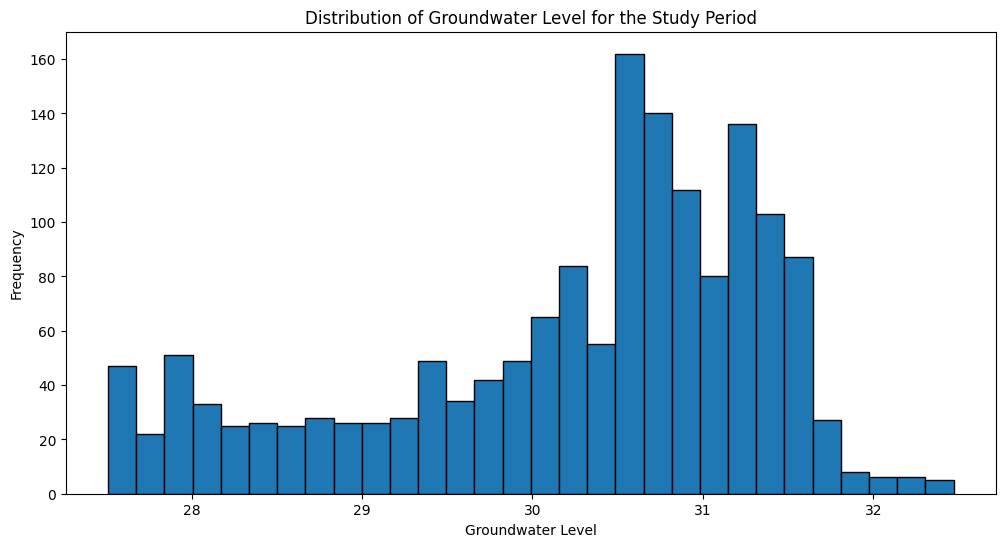

In [36]:
#Distribution of GWL for the study period
plt.figure(figsize=(12, 6))
plt.hist(df_merged["GWL"], bins=30, edgecolor="k")
plt.xlabel("Groundwater Level")
plt.ylabel("Frequency")
plt.title("Distribution of Groundwater Level for the Study Period")
plt.show()

## <span style="color: DeepSkyBlue;">Daily Groundwater and Climate Time Series Interpretation</span>
During cooler months such as fall and winter, the GWL(purple) line decreases while matching declines can be seen in tmax(red), and tmin(blue). Surface water and snowmelt take time to reach the aquifer underground which is why the data needs time to record the accumulating groundwater levels. Groundwater levels are also increased by warmer temperatures or following monsoon precipitation. 

# <span style="color: DeepSkyBlue;">Conclusion</span>

From August 2021 through December 2025, Payson’s daily temperatures averaged about 73°F for TMAX and 41°F for TMIN, while precipitation was zero on at least three-quarters of recorded days. The well’s daily groundwater depth was concentrated mostly around 30.5–31.5 feet below land surface, with noticeable variation across the study period. These results describe climate and groundwater patterns at the two nearby sites with matching correlations between lower groundwater levels and temeperatures simultaneously. 

# <span style="color: DeepSkyBlue;">References</span>
<p style="text-indent:-0.5in; margin-left:0.5in;">
National Centers for Environmental Information (NCEI). (2025). NOAA Access Data Service (v1) [Data set]. 
\hangindent=0.25in
National Oceanic and Atmospheric Administration. https://www.ncei.noaa.gov/access/services/data/v1
</p>

<p style="text-indent:-0.5in; margin-left:0.5in;">
U.S. Geological Survey. (2025). <i>USGS Water Data for the Nation: Groundwater levels via OGC API – Features</i> [Data set]. U.S. Department of \hangindent=0.25in
the Interior. https://api.waterdata.usgs.gov/ogcapi/v1
</p>
<br>